<a href="https://colab.research.google.com/github/Ahowardjr/MSSP6070/blob/main/Week_8_Assignment/WeeklyModules/Week%208.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from pathlib import Path
from IPython.display import display

from google.colab import files
files.upload()

sales = pd.read_csv("InternetSales (4).csv", encoding="cp1252", low_memory=False)
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"], format="mixed")
sales["SalesAmount"] = pd.to_numeric(sales["SalesAmount"], errors="raise")
assert sales[["OrderDate", "SalesAmount", "EnglishProductName"]].notna().all().all()
sales["Year"] = sales["OrderDate"].dt.year
print("Rows and columns:", sales.shape)
print("Date range:", sales["OrderDate"].min(), "to", sales["OrderDate"].max())

Saving InternetSales (4).csv to InternetSales (4).csv
Rows and columns: (60398, 61)
Date range: 2010-12-29 00:00:00 to 2014-01-28 00:00:00


1. Summary statistics by product
Products are ranked by total historical sales revenue. Each product name includes its color and size. The count is the number of sales records, which may differ from the number of orders.

In [2]:
# Calculate summary statistics for each individual product.
product_summary = sales.groupby("EnglishProductName").agg(
    Total_Sales=("SalesAmount", "sum"),
    Average_Sale=("SalesAmount", "mean"),
    Median_Sale=("SalesAmount", "median"),
    Sales_Records=("SalesAmount", "count"),
    Units_Sold=("OrderQuantity", "sum")
).sort_values("Total_Sales", ascending=False)
display(product_summary.head(10).round(2))
best_product = product_summary.index[0]
print(f"Highest-selling product: {best_product}")
print(f"Total historical sales: ${product_summary.iloc[0]['Total_Sales']:,.2f}")

,Total_Sales,Average_Sale,Median_Sale,Sales_Records,Units_Sold
EnglishProductName,,,,,
"Mountain-200 Black, 46",1373469.55,2215.27,2294.99,620,620
"Mountain-200 Black, 42",1363142.09,2220.10,2294.99,614,614
"Mountain-200 Silver, 38",1339462.79,2247.42,2319.99,596,596
"Mountain-200 Silver, 46",1301100.10,2243.28,2319.99,580,580
"Mountain-200 Black, 38",1294866.14,2224.86,2294.99,582,582
"Mountain-200 Silver, 42",1257434.57,2245.42,2319.99,560,560
"Road-150 Red, 48",1205876.99,3578.27,3578.27,337,337
"Road-150 Red, 62",1202298.72,3578.27,3578.27,336,336
"Road-150 Red, 52",1080637.54,3578.27,3578.27,302,302


Highest-selling product: Mountain-200 Black, 46
Total historical sales: $1,373,469.55


In [3]:
# Show all years first so partial years remain visible.
yearly_sales = sales.groupby("Year")["SalesAmount"].sum().reset_index()
display(yearly_sales.round(2))

# Exclude the partial boundary years from the fitted trend.
complete_years = yearly_sales[yearly_sales["Year"].between(2011, 2013)].copy()
display(complete_years.round(2))

,Year,SalesAmount
0,2010,43421.04
1,2011,7075525.93
2,2012,5842485.20
3,2013,16351550.34
4,2014,45694.72


,Year,SalesAmount
1,2011,7075525.93
2,2012,5842485.20
3,2013,16351550.34


In [4]:
# Use years since 2011 so the time variable starts at zero.
base_year = int(complete_years["Year"].min())
x = complete_years["Year"].to_numpy() - base_year
y = complete_years["SalesAmount"].to_numpy()
slope, intercept = np.polyfit(x, y, 1)
complete_years["Trend"] = intercept + slope * x

# Forecast five years after the last complete historical year.
last_year = int(complete_years["Year"].max())
future_years = np.arange(last_year + 1, last_year + 6)
forecast = pd.DataFrame({
    "Year": future_years,
    "Forecast_Sales": intercept + slope * (future_years - base_year)
})
display(forecast.round(2))
print(f"Estimated yearly increase: ${slope:,.2f}")

,Year,Forecast_Sales
0,2014,19032544.90
1,2015,23670557.10
2,2016,28308569.31
3,2017,32946581.52
4,2018,37584593.72


Estimated yearly increase: $4,638,012.21


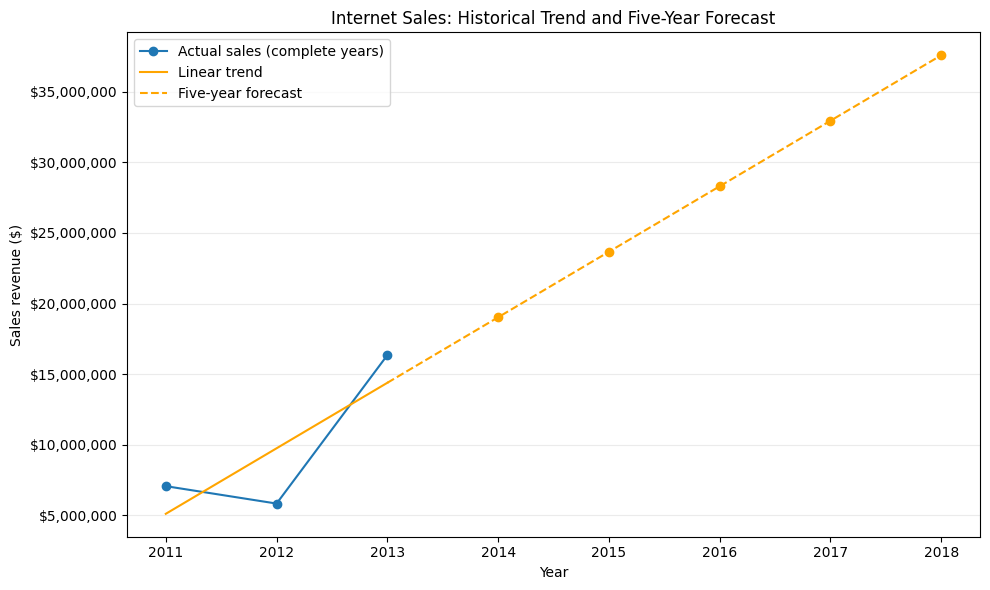

In [5]:
# Plot actual annual sales, the fitted trend, and the five-year projection.
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(complete_years["Year"], complete_years["SalesAmount"],
        marker="o", label="Actual sales (complete years)")
ax.plot(complete_years["Year"], complete_years["Trend"],
        color="orange", label="Linear trend")
projection_years = np.r_[last_year, future_years]
projection_sales = intercept + slope * (projection_years - base_year)
ax.plot(projection_years, projection_sales, "--", color="orange",
        label="Five-year forecast")
ax.scatter(future_years, forecast["Forecast_Sales"], color="orange")
ax.set(title="Internet Sales: Historical Trend and Five-Year Forecast",
       xlabel="Year", ylabel="Sales revenue ($)")
ax.set_xticks(np.arange(base_year, future_years[-1] + 1))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
# Generate a short interpretation directly from the calculated results.
print(f"Based on total historical sales, {best_product} is the strongest individual product.")
print("I expect this product to remain a strong seller if previous patterns continue.")
print("However, summary statistics do not guarantee which product will lead in future years.")
print(f"The linear model projects sales of ${forecast.iloc[0]['Forecast_Sales']:,.2f} "
      f"in {int(forecast.iloc[0]['Year'])} and "
      f"${forecast.iloc[-1]['Forecast_Sales']:,.2f} in {int(forecast.iloc[-1]['Year'])}.")
print("I would treat these figures as a starting point. More data from previos years are needed "
      "before using this forecast to make purchasing or budget decisions.")

Based on total historical sales, Mountain-200 Black, 46 is the strongest individual product.
I expect this product to remain a strong seller if previous patterns continue.
However, summary statistics do not guarantee which product will lead in future years.
The linear model projects sales of $19,032,544.90 in 2014 and $37,584,593.72 in 2018.
I would treat these figures as a starting point. More data from previos years are needed before using this forecast to make purchasing or budget decisions.
